# 10. 工具调用节点
## 10.1 工具节点的实现
工具是 **`Agent`** 扩展外部能力的重要组件之一。本节以最基础的 **`ReAct` 式工具调用循环**为例，分别介绍手动实现工具节点和使用预构建 **`ToolNode`** 两种方式。

手动实现有助于理解工具调用的基本流程：模型生成工具调用请求，工具节点根据名称查找并执行工具，再将执行结果封装成与原工具调用对应的 **`ToolMessage`**。不过，实际项目还需要处理参数校验、异常处理、运行时注入、并行执行以及 **`Command`** 传播等问题。

**`ToolNode`** 对这些通用逻辑进行了封装，适合在需要自定义图结构和工具调用流程的场景中使用。

### 10.1.1 手动处理工具调用
示例:

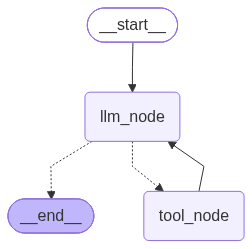

In [1]:
from typing import Literal

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

@tool(parse_docstring=True)
def get_news(home_or_abroad: bool) -> str:
    """
    查询国内外新闻

    Args:
        home_or_abroad: 查询国内还是国外新闻，True: 国内新闻，False：国外新闻
    """
    if home_or_abroad:
        return "Kimi 新模型发布"
    return "Anthropic 暂停新模型访问"

tools_by_name = {
    "get_weather": get_weather,
    "get_news": get_news
}
tools = [get_weather, get_news]
model_with_tools = model.bind_tools(tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

def tool_node(state: MessagesState) -> MessagesState:
    last_msg = state['messages'][-1]
    if not last_msg.tool_calls:
        return {}
    
    tool_msgs = []
    for tool_call in last_msg.tool_calls:
        tool = tools_by_name[tool_call["name"]]
        logger.info("工具 {} 被调用, 对应的 tool_call: {}", tool_call["name"], tool_call)
        tool_res = tool.invoke(tool_call["args"])
        print(f"tool_res:{tool_res}")
        tool_msg = ToolMessage(
            name = tool_call["name"],
            content = tool_res,
            tool_call_id = tool_call["id"]
        )
        tool_msgs.append(tool_msg)

    return {
        "messages": tool_msgs
    }

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")
graph = builder.compile()

from IPython.display import display
display(graph)

#res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻")]})


In [2]:
res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻")]})

2026-10-19 11:47:22.448 | INFO     | __main__:tool_node:77 - 工具 get_weather 被调用, 对应的 tool_call: {'name': 'get_weather', 'args': {'city': '北京'}, 'id': 'call_h0WiTegDnfwBkhFf0EAqceJh', 'type': 'tool_call'}
2026-10-19 11:47:22.449 | INFO     | __main__:tool_node:77 - 工具 get_news 被调用, 对应的 tool_call: {'name': 'get_news', 'args': {'home_or_abroad': True}, 'id': 'call_pXuA8OLE5iY0jV49f4AKzIdZ', 'type': 'tool_call'}


tool_res:北京 今天天气不错
tool_res:Kimi 新模型发布


In [3]:
rprint(res)

{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？国内有哪些新闻',
            additional_kwargs={},
            response_metadata={},
            id='154a06d6-2ef1-4a68-9c02-0dafda9b464a'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_h0WiTegDnfwBkhFf0EAqceJh',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_1792435642322_3naqptdq4y3',
                    'status': 'completed'
                },
                {
                    'arguments': '{"home_or_abroad":true}',
                    'call_id': 'call_pXuA8OLE5iY0jV49f4AKzIdZ',
                    'name': 'get_news',
                    'type': 'function_call',
                    'id': 'fc_1792435642322_klrwscwtdne',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'gen_01M5AQTM6FJ3BYS206SPGQ306C',
                'created_at': 1792435642.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='gen_01M5AQTM6FJ3BYS206SPGQ306C',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_h0WiTegDnfwBkhFf0EAqceJh',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_news',
                    'args': {'home_or_abroad': True},
                    'id': 'call_pXuA8OLE5iY0jV49f4AKzIdZ',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 96,
                'output_tokens': 51,
                'total_tokens': 147,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        ),
        ToolMessage(
            content='北京 今天天气不错',
            name='get_weather',
            id='ccc08772-0bde-460e-a047-f9f296bf13f0',
            tool_call_id='call_h0WiTegDnfwBkhFf0EAqceJh'
        ),
        ToolMessage(
            content='Kimi 新模型发布',
            name='get_news',
            id='3c078435-3cb0-41f7-a25c-18476527bc54',
            tool_call_id='call_pXuA8OLE5iY0jV49f4AKzIdZ'
        ),
        AIMessage(
            content=[
                {
                    'type': 'text',
                    'text': '- **北京天气**：今天天气不错。  \n- **国内新闻**：Kimi 发布了新模型。',
                    'annotations': [],
                    'id': 'msg_065e619bb47741e7016ad665c1375c87d090555385fe49f25e',
                    'phase': 'final_answer'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_065e619bb47741e7016ad665bb44d087d086f45cde4a16d9ae',
                'created_at': 1792435643.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_065e619bb47741e7016ad665bb44d087d086f45cde4a16d9ae',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 570,
                'output_tokens': 29,
                'total_tokens': 599,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )
  

上面的手动实现会按照 **`tool_calls`** 的顺序串行执行工具，主要用于展示底层流程。**`ToolNode`** 在同步调用中可通过执行器并行处理多个工具调用，在异步调用中则使用 **`asyncio.gather()`** 并发执行。

### 10.1.2 用`ToolNode`处理工具调用

上一节的工具节点完成了以下工作：读取最后一条 **`AIMessage`** 中的 **`tool_calls`**，根据工具名称查找并执行对应工具，再把执行结果封装成与原工具调用一一对应的 **`ToolMessage`**。

这种实现适合帮助我们理解工具调用的基本流程，但它只覆盖了最简单的场景。实际项目还需要处理无效工具名、参数校验、异常处理、运行时参数注入、**`Command`** 传播以及多个工具调用的并行执行等问题。

**`LangGraph`** 提供了预构建的 **`ToolNode`**。只需传入工具列表，它便可以完成上述所有操作。

源代码:
```python
ToolNode(
  self,
  tools: Sequence[BaseTool | Callable],
  *,
  name: str = 'tools',
  tags: list[str] | None = None,
  handle_tool_errors: bool | str | Callable[..., str] | type[Exception] | tuple[type[Exception], ...] = _default_handle_tool_errors,
  messages_key: str = 'messages',
  wrap_tool_call: ToolCallWrapper | None = None,
  awrap_tool_call: AsyncToolCallWrapper | None = None
)
```

**重要参数说明**

上面展示的是构造函数签名：`self` 不需要手动传入；`*` 后面的参数必须通过关键字指定。

| 参数 | 作用与常见用法 |
| --- | --- |
| **`tools`** | 必填，可执行工具列表，例如 `[get_weather, get_news]`。接受 `BaseTool` 实例（如 `@tool` 的结果）或普通函数，普通函数会自动转换为工具。 |
| `name` | `ToolNode` 自身的名称，默认 `"tools"`，便于识别和调试。若通过 `add_node("tool_node", ...)` 显式注册，图中的节点名使用 `"tool_node"`。 |
| `tags` | 可选的运行标签，用于链路追踪中的筛选和分类，不是业务状态字段。 |
| **`handle_tool_errors`** | 工具异常处理策略：`True` 将普通工具异常转为错误 `ToolMessage`；`False` 让异常向外抛出。还支持固定错误字符串、指定异常类型/类型元组，或自定义异常处理函数。 |
| **`messages_key`** | 状态中消息列表的字段名，默认 `"messages"`。读取模型工具调用、输出普通工具回复时都使用这个字段；继承 `MessagesState` 时通常无需修改。 |
| `wrap_tool_call` | 同步工具调用包装器，接收请求 `request` 和执行回调 `execute`，可在单次调用前后加入重试、缓存或参数改写，最终返回 `ToolMessage` 或 `Command`。后文会进一步介绍。 |
| `awrap_tool_call` | 异步工具调用包装器，对应异步执行场景，通过 `await execute(request)` 执行工具。 |

注意，**默认的 `handle_tool_errors` 并不是 `True`**：当前实现主要将模型传参不合法等工具调用错误转换为反馈消息，工具函数内部的执行异常默认仍会抛出。`GraphInterrupt` 等中断控制异常也会继续向外传播，不会作为普通工具错误吞掉。

本节最常用的是 `tools`，其次是按需求设置 `handle_tool_errors`。`ToolNode(tools)` 负责执行工具；让模型知道有哪些工具，仍需上文的 `model.bind_tools(tools)`。

参考：[ToolNode 官方源码与参数说明](https://github.com/langchain-ai/langgraph/blob/main/libs/prebuilt/langgraph/prebuilt/tool_node.py)。


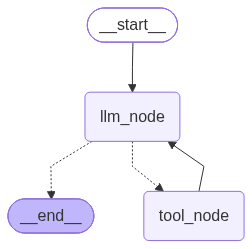

{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？国内有哪些新闻？',
            additional_kwargs={},
            response_metadata={},
            id='7969561e-0148-4e3e-8062-b29ac34faece'
        ),
        AIMessage(
            content=[
                {
                    'id': 'rs_0f22cd22e485ea00016ad6ca0c804487d0941176ebfbc0fcb6',
                    'summary': [],
                    'type': 'reasoning',
                    'content': [],
                    'encrypted_content': 
'gAAAAABq1soNBPV5Yn9shSMaY6IbkmdSlAaTdDDU7JCykI6ZLTNHXFSf5NGM1MAna950LbG5pJlgjTkdsBkQsCwGhOLqdIsOuPgqs_c94sG-VPxnnO
jVD9ux_FCS4VZrCZ1nhcC6IUkEhrf3XPanNZUw94sY__mIgo6RDX12GO7em6LdW19YxnhVEKJQpzArROXCHsAL62f0MJGIJk2s9K1poAMggU9mdNozW
wasFMy1-hodoejvRcXAIxgP4_df6cNSLfcTJp8ZRWr_v-cIVFDDeluHLbArO6vsRvnnYZHpV414ZIqZqgWO6G26yY7Iawq-KeYomAqdYWCcTgn2wPoN
GVodkrh2sMChHYrGonYm-GgPsI89TeIvJpTFZv2o-La-pMzEwQMFKcxsKQAM7C-lkQhdkLSzlX5jD8-6XgPEtC1eVBY-bQ1rk1y6wcVH1nRYTaeAkTl
QI7PAUOXbL50htQkKTYG1S_F-RvcaenTdcHZW4-jTqnE0gpIvd1k6XBRQvIjqqegc8xu0srqH3tYa-NezliG9WiPDZg2wliV1Yrt7X6QY1iHuX4wwPN
nengy2KXHPve64K9E_ZTvxawgpNzBzDKXkmCb51B_beslq5QPIdAgPai6-yV7zkMiJ9_RQC48rHif0wRRAWnbrPau8V2X9Wuhiz_NVMdSqiNnBHrF66
WOH-sNpZ5fCDlKwphFJYKf1goq8UfsrAH6gXZH_t-70Svzo2mG-MDf7VzfvURw63jnZp2M7CAmCtt2Eav8fIawOvMIlJcTAUFIylzm_qe6N2x1ja1XF
lKHezMyIlC4RzMQfj0jQvgmFgdFtMFoCwefFiZhGbSaZvOf7GCF2izB6rL5HMG2gdKpuZjPMDsJAEhUqLDthMQrPdY0kfKPWSuw9SIE_WMGsC7RoTvv
bPHwr8au3_MeChbGeFZeQetzk9DfFRE0PsjnbHgQ44N7w03QAMQMSNibCYsqKp3h3kf9Jmnth17A9GdJXlOjtWagY7fnqdK_9p035GFwMhdw8i4z-sR
zfgCGMOmPcu0qtuBH0w6Dr05lKnunl93MKsQwkymANPZAyDYSRLhsfbfGz_T7mk67xw82lNjovG1JVu0DF630Zeebs84iHQtRZ1WmisdClw68bwKMoT
fEjg-RA0ggtlv5hQ51DUQyrnSzS1e2807UG_iYmxxS84___PWoHzD1NSa-ZcZEwyZOiz8SNV9UZ2GVYewuqzbUdT8unCNUGKy4hYrUebfLtAwTbhTgH
zR10KbJy7LLhfSQfN-Gc4hn5rpzDCicBxBjHvYQsJ8P1tUiexBXTRcBKnnqR-IwhFjwmvBkqac5gRT_elLGTCAA9D49AuauPmmc94yEcICTdN9hORJ2
GpdhF7nyNYOjioglXPVeY8rdRdbJcwuDGDNp9l-Z6HMhiju7L7y8GQ-w1xuiqrvZkhNiJIeR0JczGo1ECC8T-Kq_kMAfvG6pn4DuRR5N88N7ibkIjT1
pRFqMH9raXm5NnSHqOoR8QB8rUw-I50xCXuvHq0Dz-mT8Cld1_RFu2tHkJeG_xhhFpTQPigSBLVGhNTYoJlPX_R-ZHuFSvyudhMe8mYD57cog48fHLI
HEP1GR1A5WZX02RW3mKbyOwda94Vlf8XKzjGyaNSOFoIzsdYmZ-SDZJt-92Hbwu1E3Y1Q6ghgKQJfDFBHlwtspa7w=='
                },
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_3uq4nYvp8AvnSz8RMCzgOE59',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_0f22cd22e485ea00016ad6ca0dae5487d0829d0454e73c84c8',
                    'status': 'completed'
                },
                {
                    'arguments': '{"home_or_abroad":true}',
                    'call_id': 'call_KIdoasN1BzIKGw67zD5dST6O',
                    'name': 'get_news',
                    'type': 'function_call',
                    'id': 'fc_0f22cd22e485ea00016ad6ca0dae7c87d0af03c2e578671820',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_0f22cd22e485ea00016ad6ca07dc1487d08666717c4505fcd9',
                'created_at': 1792461319.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_0f22cd22e485ea00016ad6ca07dc1487d08666717c4505fcd9',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_3uq4nYvp8AvnSz8RMCzgOE59',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_news',
                    'args': {'home_or_abroad': True},
                    'id': 'call_KIdoasN1BzIKGw67zD5dST6O',
                    'type':

In [1]:
from typing import Literal

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.prebuilt import ToolNode
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

@tool(parse_docstring=True)
def get_news(home_or_abroad: bool) -> str:
    """
    查询国内外新闻

    Args:
        home_or_abroad: 查询国内还是国外新闻，True: 国内新闻，False：国外新闻
    """
    if home_or_abroad:
        return "Kimi 新模型发布"
    return "Anthropic 暂停新模型访问"

tools_by_name = {
    "get_weather": get_weather,
    "get_news": get_news
}
tools = [get_weather, get_news]
model_with_tools = model.bind_tools(tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻？")]})

rprint(res)

## 10.2 进阶用法
### 10.2.1 `ToolRuntime`介绍
**`ToolRuntime`** 是专门面向工具调用的运行时对象。

按照官方规范：

- 工具函数中存在名为 **`runtime`**
- 并且类型标注为 **`ToolRuntime`** 的参数时

这个有点像中间件提供的Runtime 参数。但需要注意，**`ToolRuntime`** 与图节点中使用的 **`langgraph.runtime.Runtime`** 并不是同一个类型。前者额外提供了当前图状态、运行配置和工具调用 ID 等工具调用专属信息。

```python
ToolRuntime(
  self,
  state: StateT,
  context: ContextT,
  config: RunnableConfig,
  stream_writer: StreamWriter,
  tool_call_id: str | None,
  store: BaseStore | None,
  tools: list[BaseTool] = list(),
  execution_info: ExecutionInfo | None = None,
  server_info: ServerInfo | None = None
)
```

- **`state`**：图状态，短期记忆
- **`context`**：运行时上下文
- **`config`**：运行时配置，包含元数据
- **`stream_writer`**：自定义流式输出写入器
- **`tool_call_id`**：工具调用 **`ID`**
- **`store`**：长期记忆

借助 **`runtime`**，工具可以访问上述所有资源。

### 10.2.2 在工具中更新状态
在工具的实现函数，除了普通的字符串、python类型，还可以返回 **`Command(update=...)`**，将业务结果写入图状态。

但工具返回 **`Command`** 时，运行结果到 **`ToolMessage`** 的转换操作需要开发者完成，此时还应在 **`Command.update`** 的消息字段中写入对应的 **`ToolMessage`**。

为什么返回普通结果时可以自动包装，而 Command 需要自己提供消息？因为执行链路会将普通字符串、字典等转换为工具回复；遇到 Command 时，则保留它的状态更新、跳转等控制语义，交给图运行时处理。ToolNode 随后检查其中是否存在匹配本次调用的 ToolMessage，缺少时会报错

注意:在目前最新版本中`langgraph 1.2.16`,`langgraph-prebuilt 1.1.1`。

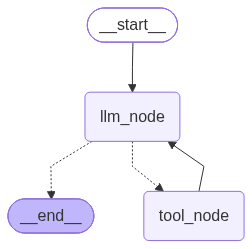

{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？国内有哪些新闻？',
            additional_kwargs={},
            response_metadata={},
            id='62b2796e-810e-4a9e-a302-01db309c7242'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_iyjMyASwi505DyuGVUQtYmGn',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_1792463104731_nqp858k9fkp',
                    'status': 'completed'
                },
                {
                    'arguments': '{"home_or_abroad":true}',
                    'call_id': 'call_lrpyK1xSKnDoiRbJf7EzzAkf',
                    'name': 'get_news',
                    'type': 'function_call',
                    'id': 'fc_1792463104731_bvzvmko33gv',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'gen_01M5BJ0S5Q2BXY3TDAMMAYVAH9',
                'created_at': 1792463104.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='gen_01M5BJ0S5Q2BXY3TDAMMAYVAH9',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_iyjMyASwi505DyuGVUQtYmGn',
                    'type': 'tool_call'
                },
                {
                    'name': 'get_news',
                    'args': {'home_or_abroad': True},
                    'id': 'call_lrpyK1xSKnDoiRbJf7EzzAkf',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 97,
                'output_tokens': 51,
                'total_tokens': 148,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        ),
        ToolMessage(
            content='北京 今天天气不错',
            name='get_weather',
            id='b3b582c0-bc1d-4747-9d35-843b0a3bd02b',
            tool_call_id='call_iyjMyASwi505DyuGVUQtYmGn'
        ),
        ToolMessage(
            content='Kimi 新模型发布',
            name='get_news',
            id='cea9d790-d302-4bf4-82c1-1037bb6e9e16',
            tool_call_id='call_lrpyK1xSKnDoiRbJf7EzzAkf'
        ),
        AIMessage(
            content=[
                {
                    'type': 'text',
                    'text': '- **北京今天天气**：今天天气不错。  \n- **国内新闻**：Kimi 发布了新模型。',
                    'annotations': [],
                    'id': 'msg_063dc595d2dce13f016ad6d10670ec87d0848eb455bd3a63f4',
                    'phase': 'final_answer'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_063dc595d2dce13f016ad6d101bc9087d0abea4021309bad6a',
                'created_at': 1792463105.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_063dc595d2dce13f016ad6d101bc9087d0abea4021309bad6a',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 571,
                'output_tokens': 31,
                'total_tokens': 602,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )

In [ ]:
from typing import Literal
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.prebuilt import ToolNode, ToolRuntime
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(MessagesState):
    weather_res: str
    news_res: str

@tool(parse_docstring=True)
def get_weather(city: str, runtime: ToolRuntime) -> Command:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    res = f"{city} 今天天气不错"
    tool_call_id = runtime.tool_call_id
    tool_msg = ToolMessage(tool_call_id=tool_call_id, content=res)
    return Command(
        update = {
            "weather_res": res,
            "messages": [tool_msg]
        }
    )

@tool(parse_docstring=True)
def get_news(home_or_abroad: bool, runtime: ToolRuntime) -> Command:
    """
    查询国内外新闻

    Args:
        home_or_abroad: 查询国内还是国外新闻，True: 国内新闻，False：国外新闻
    """
    if home_or_abroad:
        res = "Kimi 新模型发布"
    else:
        res = "Anthropic 暂停新模型访问"
    tool_call_id = runtime.tool_call_id
    tool_msg = ToolMessage(tool_call_id=tool_call_id, content=res)
    return Command(
        update = {
            "news_res": res,
            "messages": [tool_msg]
        }
    )

tools = [
    get_weather,
    get_news
]
model_with_tools = model.bind_tools(tools)

def llm_node(state: OverAllState) -> OverAllState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: OverAllState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻？")]})
rpres = res["messages"]
# 返回的State 报看message 和 我们自定义的2个字段
rprint(res)

### 10.2.3 工具节点执行与容错机制
**`ToolNode`** 提供同步工具调用包装器 **`wrap_tool_call`**，用于在工具执行前后插入自定义逻辑。

它与 **`LangChain Agent`** 中间件 **`wrap_tool_call`** 的核心机制相同：接收当前工具调用请求 **`request`** 和真正执行工具的回调 **`execute`**，可以选择不调用、调用一次或多次 **`execute(request)`**，并最终返回 **`ToolMessage`** 或 **`Command`**。

因此，**`wrap_tool_call`** 可以用于重试、缓存、请求改写、短路返回和自定义控制流等场景。异步工具链路还可以使用对应的 **`awrap_tool_call`**。

此处通过重试和缓存机制的实现，介绍 **`wrap_tool_call`** 的用法。

对于 wrap_tool_call, Langgraph 的定义是:
```python
ToolCallWrapper = Callable[[ToolCallRequest, Callable[[ToolCallRequest], ToolMessage | Command]], ToolMessage | Command]
```

1. 重试机制

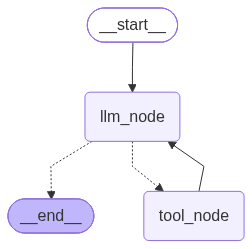

In [7]:
from dataclasses import dataclass
import random
from typing import Literal
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.prebuilt import ToolNode, ToolRuntime
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from loguru import logger
from rich import print as rprint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)
@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    # 70% 概率因网络波动而调用失败
    rand_int = random.randint(1,10)
    if rand_int < 8:
        raise ConnectionError("网络波动失败")
    return f"{city} 今天天气不错"

tools = [get_weather]
model_with_tools = model.bind_tools(tools=tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

@dataclass
class UserContext:
    max_attempts: int

def wrap_tool_call(request, execute):
    max_attempts = request.runtime.context.max_attempts
    tool_call_id = request.runtime.tool_call_id

    tool_msg = ""
    for i in range(max_attempts):
        try:
            tool_msg = execute(request)
            break
        except ConnectionError as e:
            logger.info("工具调用失败，当前调用次数: {}, 调用次数上限: {}, 异常信息: {}", i + 1, max_attempts, e)

    if not tool_msg:
        tool_msg = ToolMessage(
            tool_call_id = tool_call_id,
            content = "调用次数到达上限，调用失败"
        )

    return tool_msg

builder = StateGraph(state_schema=MessagesState, context_schema=UserContext)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools, wrap_tool_call=wrap_tool_call))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

In [9]:
res = graph.invoke(
    {"messages": [HumanMessage("今天北京天气如何？")]},
    context = UserContext(max_attempts=3))
rprint(res)

2026-10-19 20:33:12.738 | INFO     | __main__:wrap_tool_call:71 - 工具调用失败，当前调用次数: 1, 调用次数上限: 3, 异常信息: 网络波动失败


{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='7b5282a0-fe5f-4e12-9bac-3de645840a04'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_A4UJUeSZT9Ad2SKDQwb1iPK6',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_1792467192681_0zzsv5kdh0se',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'gen_01M5BNXHPG5A62Y2B6DNCCNZZP',
                'created_at': 1792467192.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='gen_01M5BNXHPG5A62Y2B6DNCCNZZP',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_A4UJUeSZT9Ad2SKDQwb1iPK6',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 54,
                'output_tokens': 18,
                'total_tokens': 72,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        ),
        ToolMessage(
            content='北京 今天天气不错',
            name='get_weather',
            id='31dd5e6e-6592-4306-b764-7002ff784db3',
            tool_call_id='call_A4UJUeSZT9Ad2SKDQwb1iPK6'
        ),
        AIMessage(
            content=[
                {
                    'type': 'text',
                    'text': '北京今天天气不错。',
                    'annotations': [],
                    'id': 'msg_0cd015dce023527c016ad6e0ffef1487d09d016f424dd9dd81',
                    'phase': 'final_answer'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_0cd015dce023527c016ad6e0f9b9c887d0be8f613e944d6613',
                'created_at': 1792467193.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_0cd015dce023527c016ad6e0f9b9c887d0be8f613e944d6613',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 481,
                'output_tokens': 10,
                'total_tokens': 491,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )
    ]
}

2. 实现缓存机制

**排错提示：本节需要创建自己的工具列表，并让模型与 ToolNode 使用同一份列表。**

```python
tools = [get_weather]
model_with_tools = model.bind_tools(tools)
# 构图时使用 ToolNode(tools=tools, wrap_tool_call=wrap_tool_call)
```

曾遇到的两个错误对应不同阶段：

- **`TypeError: 'StructuredTool' object is not subscriptable`**：原先使用 `model.bind(tools=[get_weather])`，它只绑定参数，不把工具对象转换为模型接口需要的工具描述。请求组装时按字典读取 `tool["type"]`，因此在 `llm_node` 中报错。应使用 `bind_tools()`。
- **修正绑定后出现 `ConnectionError: 网络波动失败`**：本节重新定义了 `get_weather`，但没有重新创建 `tools` 列表。Jupyter 中旧列表仍指向上一节随机抛错的工具对象；`ToolNode(tools=tools)` 因而执行了旧工具。应在本节重新写 `tools = [get_weather]`。独立执行本节时，这也能避免 `tools` 未定义。

修改后，依次重新运行本节的“工具与缓存定义”和“构图与调用”两个代码单元格；重建图才能更新其中注册的工具。


In [17]:
from dataclasses import dataclass
import json
import random
from typing import Literal
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.prebuilt import ToolNode, ToolRuntime
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from loguru import logger
from rich import print as rprint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

tools = [get_weather]
model_with_tools = model.bind_tools(tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END


global_cache = dict()
def wrap_tool_call(request, execute):
    tool_name = request.tool_call["name"]
    tool_args = json.dumps(request.tool_call["args"])
    # 更新工具调用ID
    tool_call_id = request.runtime.tool_call_id

    cache_key = (tool_name, tool_args)
    cache = global_cache.get(cache_key)
    # 从下面的定义可知,excute的返回值是ToolMessage ｜ Command
    if cache:
        # 缓存只保存正文，命中时需构造匹配本次调用 ID 的消息
        logger.info("{} 调用命中缓存", tool_name)
        tool_msg = ToolMessage(
            tool_call_id = tool_call_id,
            content = cache
        )
    else:
        # 未命中时，execute 已经返回本例所需的 ToolMessage
        tool_msg = execute(request)
        logger.info("将 {} 的调用结果写入缓存", tool_name)
        global_cache[cache_key] = tool_msg.content

    return tool_msg

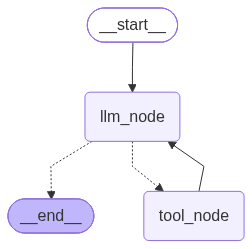

============================== -> 第一次调用 - 北京 <- ==============================


2026-10-19 21:47:58.503 | INFO     | __main__:wrap_tool_call:76 - 将 get_weather 的调用结果写入缓存


{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='ae38b454-9808-4acd-a7f8-ec1feff25ffe'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_DdhTcErE0gwmupEQ330voRdH',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_0ee63b184e6a9400016ad6f27e2f2887d0ba9e45bb041d5e6c',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_0ee63b184e6a9400016ad6f275098087d0873419d5799fb8fe',
                'created_at': 1792471669.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_0ee63b184e6a9400016ad6f275098087d0873419d5799fb8fe',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_DdhTcErE0gwmupEQ330voRdH',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 447,
                'output_tokens': 18,
                'total_tokens': 465,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        ),
        ToolMessage(
            content='北京 今天天气不错',
            name='get_weather',
            id='b4024544-34af-4be5-9593-84ea775924ca',
            tool_call_id='call_DdhTcErE0gwmupEQ330voRdH'
        ),
        AIMessage(
            content=[
                {
                    'type': 'text',
                    'text': '北京今天天气不错。',
                    'annotations': [],
                    'id': 'msg_1792471682138_43xb2f3qnyi',
                    'phase': 'final_answer'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'gen_01M5BT6GGC4QPE7P8HYZ9ZAGP5',
                'created_at': 1792471682.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='gen_01M5BT6GGC4QPE7P8HYZ9ZAGP5',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 88,
                'output_tokens': 10,
                'total_tokens': 98,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )
    ]
}

In [18]:
builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools, wrap_tool_call=wrap_tool_call))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

print('=' * 30, '-> 第一次调用 - 北京 <-', '=' * 30)
res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？")]})
rprint(res)

In [19]:
print('=' * 30, '-> 第二次调用 - 北京 <-', '=' * 30)
res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？")]})
rprint(res)

============================== -> 第二次调用 - 北京 <- ==============================


2026-10-19 21:48:40.941 | INFO     | __main__:wrap_tool_call:68 - get_weather 调用命中缓存


{
    'messages': [
        HumanMessage(
            content='今天北京天气如何？',
            additional_kwargs={},
            response_metadata={},
            id='dd931838-6bc1-430f-9bbf-eccb0df561f2'
        ),
        AIMessage(
            content=[
                {
                    'arguments': '{"city":"北京"}',
                    'call_id': 'call_2F5FGuKJhqPJ506rQzoC24vu',
                    'name': 'get_weather',
                    'type': 'function_call',
                    'id': 'fc_004af515d80997e2016ad6f2a87fc087d0b45845015aa5b558',
                    'status': 'completed'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'resp_004af515d80997e2016ad6f2970d9c87d0b4c57f0e75148017',
                'created_at': 1792471703.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='resp_004af515d80997e2016ad6f2970d9c87d0b4c57f0e75148017',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_2F5FGuKJhqPJ506rQzoC24vu',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 447,
                'output_tokens': 18,
                'total_tokens': 465,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        ),
        ToolMessage(
            content='北京 今天天气不错',
            id='0d594b8e-9d38-4f1a-804f-6da3953cdca7',
            tool_call_id='call_2F5FGuKJhqPJ506rQzoC24vu'
        ),
        AIMessage(
            content=[
                {
                    'type': 'text',
                    'text': '北京今天天气不错。',
                    'annotations': [],
                    'id': 'msg_1792471724381_aaiorwqh49t',
                    'phase': 'final_answer'
                }
            ],
            additional_kwargs={},
            response_metadata={
                'id': 'gen_01M5BT7T0JXJMW4DP7HV0HNZKP',
                'created_at': 1792471724.0,
                'metadata': {},
                'model': 'gpt-6-luna',
                'object': 'response',
                'service_tier': 'default',
                'status': 'completed',
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna'
            },
            id='gen_01M5BT7T0JXJMW4DP7HV0HNZKP',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 88,
                'output_tokens': 10,
                'total_tokens': 98,
                'input_token_details': {'cache_creation': 0, 'cache_read': 0},
                'output_token_details': {'reasoning': 0}
            }
        )
    ]
}

# 总结
1. 静态断点 和 动态断点
2. 动态断点在函数内使用 interrupt()
3. 静态断点指定 interrupt_before() 和 interrupt_after
4. 工程部署使用 LangSmith 和 LangChatUI
5. 工具节点 ToolNode()

# 问题

### 1. 普通节点、ToolNode 和工具函数的参数注入有什么异同？


**能访问相似的运行信息，但需要区分“图节点”和“工具函数”两层。**

**（1）先区分调用位置**

在上文 `builder.add_node("tool_node", ToolNode(tools))` 中：

- **`ToolNode` 是图节点**，与普通节点一样接收图的输入、运行配置和 `Runtime`。如果手写工具节点，也可以使用 `def tool_node(state: State, config: RunnableConfig, runtime: Runtime[Context])` 这样的签名。
- **`get_weather` 等 `@tool` 函数是节点内部执行的工具**，使用 `runtime: ToolRuntime` 接收工具运行信息，不能直接照搬普通节点的三参数写法。

严格说，普通节点的 `state` 是图传入的节点输入；`config`、`runtime` 是额外提供的运行参数。

**（2）再对照信息的读取方式**

| 信息 | 普通节点 / 手写工具节点 | `@tool` 工具函数 |
| --- | --- | --- |
| 图状态 | `state` 参数 | `runtime.state` |
| 运行配置 | `config` 参数 | `runtime.config`，也支持单独声明 `config: RunnableConfig` |
| 业务上下文 | `runtime.context` | `runtime.context` |
| 长期存储 | `runtime.store` | `runtime.store` |
| 流式输出函数 | `runtime.stream_writer` | `runtime.stream_writer` |
| 当前工具调用 ID | 图的 `Runtime` 不直接提供 | `runtime.tool_call_id` |

表中的同名 `runtime`，在图节点中是 **`Runtime`**，在工具函数中是 **`ToolRuntime`**；它们是不同的类型。

**（3）理解 ToolNode 在中间做了什么**

```text
图传入状态、config 和 Runtime
              ↓
           ToolNode
              ↓ 为每次工具调用加入 tool_call_id 等信息
          ToolRuntime
              ↓
    注入 get_weather 等工具函数
```

`ToolRuntime` 中的上下文、存储和流式输出能力来自图的 `Runtime`，同时增加图状态、配置和本次工具调用 ID 等信息。工具中的 `runtime: ToolRuntime` 不会暴露给模型；例如上文 `get_weather(city, runtime)`，模型只需提供 `city`。

使用时注意：

- **仅在工具函数里写 `state: State`，不会自动获得图状态**，它会被当作普通工具入参。优先通过 `runtime.state` 读取；也有显式的 `InjectedState` 注入方式。
- **单独声明 `config: RunnableConfig` 仍然有效**，但通常读取 `runtime.config` 就足够了。工具的运行时参数应使用 `ToolRuntime`，不要换成图节点使用的 `Runtime[Context]`。
- **手动调用 `tool.invoke(tool_call["args"])` 不会自动完成 ToolNode 的运行信息注入**。当工具依赖 `ToolRuntime` 时，应使用 `ToolNode` 等提供注入能力的执行链路；自定义工具节点则需要自行处理。

参考：[图节点参数](https://docs.langchain.com/oss/python/langgraph/graph-api#nodes)、[工具运行时与状态访问](https://docs.langchain.com/oss/python/langchain/tools#access-context)。本说明已在 `langgraph 1.2.16`、`langgraph-prebuilt 1.1.1` 环境核对。


### 2. 工具调用中的 context 如何传递？它有默认字段吗？


**这里的 `context` 就是以前学过的运行时上下文：由调用方提供本次运行使用的条件和依赖，普通节点、中间件和工具执行链路都可以读取。**

**（1）联系旧项目：从中间件的用户名，到工具包装器的重试上限**

在 `lang-chain-learn` 的 [07-自定义中间件.ipynb](/Users/skk/Developer/lang-chain-learn/Chapter08_Middleware/07-自定义中间件.ipynb) **5.3.3、5.3.4** 中，我们已经用 `context_schema` 声明上下文，并传入用户名“小明”，让 `before_model` 通过 `runtime.context.user_name` 读取。

当前示例使用的是相同机制，只是配置内容和读取位置变了：

| 场景 | 声明位置 | 调用时传入 | 执行时读取 |
| --- | --- | --- | --- |
| 旧项目的中间件 | `create_agent(..., context_schema=UserContext)` | `context=UserContext(user_name="小明")` | `runtime.context.user_name` |
| 当前工具重试包装器 | `StateGraph(..., context_schema=UserContext)` | `context=UserContext(max_attempts=3)` | `request.runtime.context.max_attempts` |

`create_agent` 内部也是基于 `StateGraph` 构建执行图，所以这两处使用的是同一套上下文传递机制。

**（2）为什么包装器要多写一层 request？**

旧项目 [09-自定义中间件-Wrap-style hooks.ipynb](</Users/skk/Developer/lang-chain-learn/Chapter08_Middleware/09-自定义中间件-Wrap-style hooks.ipynb>) 的 **5.4.5** 已介绍：`wrap_tool_call` 收到的是 `ToolCallRequest`，其中 `request.runtime` 是 `ToolRuntime`。

传递过程可以压缩为：

```text
invoke(context=UserContext(max_attempts=3))
    → 图的 Runtime.context
    → ToolNode 创建 ToolRuntime，使用 context=runtime.context
    → ToolCallRequest.runtime.context
    → 包装器读取 request.runtime.context.max_attempts，得到 3
```

旧项目 [08_long_memory_agent.ipynb](/Users/skk/Developer/lang-chain-learn/Chapter09_memory/08_long_memory_agent.ipynb) 的“第四步：tools 节点注入 runtime”也展示过 `context=runtime.context` 这一步；当时重点是 `store`，现在用到了同一对象上的 `context`。

旧笔记的 `handler(request)` 与当前的 `execute(request)` 都表示继续执行工具。**重试来自包装器的 `for` 循环和异常处理，不是定义了 `max_attempts` 后框架就自动重试。** 当前值为 `3`，表示每个工具调用最多尝试三次，包括第一次执行。

**（3）context 没有框架自动附加的默认字段**

本例中：

```python
@dataclass
class UserContext:
    max_attempts: int
```

传入 `UserContext(max_attempts=3)` 后，`runtime.context` 就是这个对象，只有我们声明的 `max_attempts` 字段。框架不会自动向里面添加 `thread_id`、`store` 或工具调用 ID。

需要区分**自定义的 context**和**外层 ToolRuntime 的框架字段**：

| 读取位置 | 内容来源 |
| --- | --- |
| `request.runtime.context.max_attempts` | 我们定义并传入的运行条件 |
| `request.runtime.tool_call_id` | 框架提供的当前工具调用 ID |
| `request.runtime.execution_info` | 框架提供的线程、运行和节点尝试次数等信息 |
| `request.runtime.config` | 本次执行的运行配置 |
| `request.runtime.store` | 配置给图的存储对象；未配置时通常为 `None` |

可以给自定义字段设置默认值，例如 `max_attempts: int = 3`，但这只是 `UserContext()` 的默认值。**仅声明 `context_schema=UserContext` 不会让框架自动创建该对象**；普通图调用不传 `context` 时，`runtime.context` 为 `None`。

**（4）联系记忆章节：运行条件与执行数据分开放**

- **Context**：本次调用使用的用户名、功能开关、重试上限等条件；通常作为运行期间的固定配置。
- **State**：消息、工具结果等执行中变化的数据；配置检查点后可按线程恢复。
- **Store**：需要跨会话保存的用户资料、偏好等长期数据。

这对应当前项目 [03-graph_memory.ipynb](/Users/skk/Developer/langgraph_learn/notebooks/chapter03/03-graph_memory.ipynb) 的 **7.3**，以及旧项目 [01_memory概述.ipynb](/Users/skk/Developer/lang-chain-learn/Chapter09_memory/01_memory概述.ipynb) 的 **1.2.2**。**Context 不由检查点自动恢复**：即使使用相同的 `thread_id`，下一次调用或中断恢复仍需重新传入所需的上下文。

参考：[官方 Context 说明](https://docs.langchain.com/oss/python/langchain/tools#context)。


### 3. `wrap_tool_call` 的参数和返回值类型固定吗？


**参数的个数和顺序固定；返回值类型是约定，运行时不检查，但必须遵守。**

**（1）源码定义**

```python
ToolCallWrapper = Callable[
    [ToolCallRequest, Callable[[ToolCallRequest], ToolMessage | Command]],
    ToolMessage | Command,
]
```

| 位置 | 类型 | 说明 |
| --- | --- | --- |
| 第 1 个参数 `request` | `ToolCallRequest` | 包含 `tool_call`、`tool`、`state`、`runtime`（`ToolRuntime`）；改请求用 `request.override(tool_call=...)` |
| 第 2 个参数 `execute` | `Callable[[ToolCallRequest], ToolMessage \| Command]` | ToolNode 临时定义的执行函数，可以调用 0 次、1 次或多次 |
| 返回值 | `ToolMessage \| Command` | 本次工具调用的最终结果 |

**（2）ToolNode 如何调用它**

`ToolNode._run_one()` 为每个工具调用创建 `ToolCallRequest`，再按位置调用 `self._wrap_tool_call(tool_request, execute)`。因此：

- **参数名随意，个数和顺序固定**：只接收 1 个参数会报 `TypeError`。
- **类型注解可选**：Python 不强制检查。需要注解时，`ToolCallRequest` 要从 `langgraph.prebuilt.tool_node` 导入。
- **返回值不做类型检查**：返回 `str` 会被 `messages` 的合并规则变成 `HumanMessage`；返回 `None` 会报错。
- **`execute` 是否抛异常取决于 `handle_tool_errors`**：默认值只把参数校验错误转成消息，其他异常照常抛出，所以 10.2.3 的 `except ConnectionError` 能触发重试；设为 `True` 时，异常在 `execute` 内部已变成 `status="error"` 的 `ToolMessage`，重试应改为检查 `result.status`。

下面的实验不调用模型，手写一条带 `tool_calls` 的 `AIMessage` 直接交给 `ToolNode`。本说明已在 `langgraph 1.2.16`、`langgraph-prebuilt 1.1.1` 环境核对。

In [10]:
from langchain.messages import AIMessage, ToolMessage
from langchain.tools import tool
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode

attempts = []


@tool
def weather(city: str) -> str:
    """查询天气"""
    return f"{city} 今天天气不错"


@tool
def flaky_weather(city: str) -> str:
    """查询天气，总是网络失败"""
    attempts.append(city)
    raise ConnectionError("网络波动失败")


def run(tool_obj, wrapper, **kwargs):
    # 不调用模型：手写一条带 tool_calls 的 AIMessage，直接交给 ToolNode
    ai_msg = AIMessage(content="", tool_calls=[{"name": tool_obj.name, "args": {"city": "北京"}, "id": "call_1"}])
    builder = StateGraph(MessagesState)
    builder.add_node("tool_node", ToolNode([tool_obj], wrap_tool_call=wrapper, **kwargs))
    builder.add_edge(START, "tool_node")
    builder.add_edge("tool_node", END)
    return builder.compile().invoke({"messages": [ai_msg]})["messages"][-1]


# 1. 两个参数分别是什么
def show_args(request, execute):
    print("request:", type(request).__name__, request.tool_call["args"], type(request.runtime).__name__)
    result = execute(request)
    print("execute 返回:", type(result).__name__, result.content)
    return result


run(weather, show_args)

# 2. 参数个数固定
try:
    run(weather, lambda request: request)
except TypeError as e:
    print("只接收 1 个参数:", e)

# 3. 返回值不做类型检查
print("返回 str:", type(run(weather, lambda req, ex: "直接返回字符串")).__name__)
try:
    run(weather, lambda req, ex: None)
except Exception as e:
    print("返回 None:", type(e).__name__)


# 4. handle_tool_errors 决定 execute 是否抛异常
def retry(request, execute):
    for _ in range(3):
        try:
            return execute(request)
        except ConnectionError:
            pass
    return ToolMessage("调用次数到达上限，调用失败", tool_call_id=request.tool_call["id"])


for kwargs in ({}, {"handle_tool_errors": True}):
    attempts.clear()
    msg = run(flaky_weather, retry, **kwargs)
    print(f"{kwargs or '默认值'}: 工具调用 {len(attempts)} 次, status={msg.status}")

request: ToolCallRequest {'city': '北京'} ToolRuntime
execute 返回: ToolMessage 北京 今天天气不错
只接收 1 个参数: <lambda>() takes 1 positional argument but 2 were given
返回 str: HumanMessage
返回 None: NotImplementedError
默认值: 工具调用 3 次, status=success
{'handle_tool_errors': True}: 工具调用 1 次, status=error
